## Linear Regression Model

This notebook trains and evaluates a Linear Regression model to predict combined vehicle fuel consumption in litres per 100 km.

The cleaned dataset and shared feature definitions are loaded from the project setup file so that the same features and train/test split can be reused more consistently across different models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from data_setup import (
    load_data,
    get_train_test_split,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)

### Train/Test Split
Linear Regression is used as the first baseline model. The cleaned dataset is divided into training and testing data using an 80/20 split.

The training set is used to fit the model, while the test set is kept separate so that the model can be evaluated on data it has not seen during training.

In [2]:
df = load_data()

X_train, X_test, y_train, y_test = get_train_test_split(df)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Duplicate rows removed: 10867
Training rows: 19288
Testing rows: 4823


### Preprocessing

The model uses both numerical and categorical vehicle attributes. Linear Regression can't handle the categorical values and requires numerical input so we use OnehotEncoding. This creates a seperate binary feature for each category, such as `fuel type`, `transmission type` and `vehicle class`.

The numerical features are passed through unchanged. `handle_unknown="ignore"` is used so that an unseen category in the test data does not cause an error.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES
        ),
        (
            "numeric", "passthrough", NUMERIC_FEATURES
        )
    ]
)

### Training the Model

A scikit-learn pipeline combines the preprocessing step with the Linear Regression model. This ensures that the same transformations are applied consistently before the model is trained.

The model is fitted using the training data and then used to predict fuel consumption for the test set.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['year','engine_cylinders','engine_displacement',...,'transmission', 'turbocharger','fuel_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically

### Model Evaluation

The model is Evaluated using three metrics:

- **MAE**
- **RMSE**
- **R²**

In [5]:
y_pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f} L/100 km")
print(f"RMSE: {rmse:.3f} L/100 km")
print(f"R²: {r2:.3f}")


MAE: 0.952 L/100 km
RMSE: 1.356 L/100 km
R²: 0.815


### Inspecting Predictions

To look beyond the overall evaluation metrics, the actual and predicted fuel-consumption values are compared directly.

A positive error means that the model underestimated fuel consumption, while a negative error means that it overestimated it.

In [6]:
results = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})

results.to_csv("../results/linear_regression_results.csv")

results["error"] = results["actual"] - results["predicted"]

results.head(20)

,actual,predicted,error
14532,13.067500,12.700054,0.367446
199,23.521500,19.513903,4.007597
8086,11.760750,12.748536,-0.987786
17477,10.691591,10.574694,0.116897
20575,11.200714,10.889156,0.311558
23648,12.379737,11.719150,0.660586
22945,13.067500,13.153252,-0.085752
5259,11.760750,12.290201,-0.529451
13421,9.046731,9.142877,-0.096147
17731,12.379737,11.646184,0.733553


### Prediction Errors

The plot below shows prediction error against actual fuel consumption.

Values close to zero represent more accurate predictions. The plot also helps identify whether the model becomes systematically less accurate for particular levels of fuel consumption.

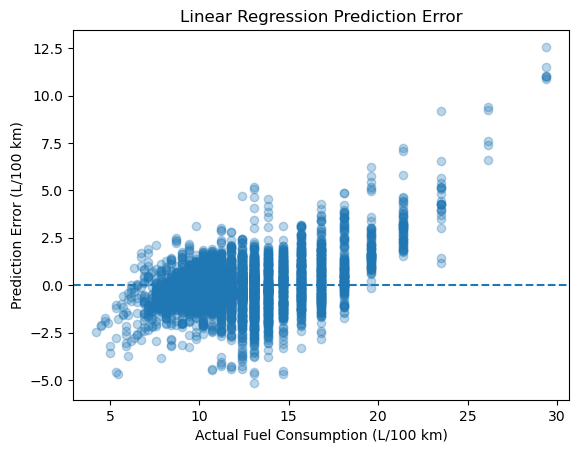

In [7]:
plt.scatter(results["actual"], results["error"], alpha=0.3)
plt.axhline(0, linestyle="--")

plt.xlabel("Actual Fuel Consumption (L/100 km)")
plt.ylabel("Prediction Error (L/100 km)")
plt.title("Linear Regression Prediction Error")

plt.show()

### Largest Prediction Errors

The observations with the largest absolute prediction errors are examined to identify where the Linear Regression model performs poorly.

This can help distinguish between possible data-quality issues and limitations of the model itself.

In [8]:
results["absolute_error"] = results["error"].abs()

worst_errors = results.sort_values(
    "absolute_error",
    ascending=False
).head(20)

worst_errors

,actual,predicted,error,absolute_error
945,29.401875,16.837116,12.564759,12.564759
7676,29.401875,17.912203,11.489672,11.489672
1747,29.401875,18.351489,11.050386,11.050386
1056,29.401875,18.368257,11.033618,11.033618
2467,29.401875,18.413766,10.988109,10.988109
1053,29.401875,18.545565,10.856310,10.856310
3302,26.135000,16.755776,9.379224,9.379224
1880,26.135000,16.887575,9.247425,9.247425
6072,23.521500,14.358697,9.162803,9.162803
1748,26.135000,18.542035,7.592965,7.592965


The largest errors are concentrated mainly among vehicles with very high fuel consumption. Many of these vehicles have large engines, high cylinder counts, or are older vehicles.

The model tends to underpredict these extreme values. This suggests that the relationship between the vehicle characteristics and fuel consumption may not be fully linear, rather than indicating an obvious issue with the cleaned data.

In [9]:
worst_indices = worst_errors.index

worst_cases = X_test.loc[worst_indices].copy()

worst_cases["actual"] = y_test.loc[worst_indices]
worst_cases["predicted"] = results.loc[worst_indices, "predicted"]
worst_cases["absolute_error"] = results.loc[worst_indices, "absolute_error"]

worst_cases

,year,engine_cylinders,engine_displacement,class,drive,transmission,turbocharger,fuel_type,actual,predicted,absolute_error
945,1985,8.0,4.9,Midsize Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,16.837116,12.564759
7676,1995,12.0,4.7,Two Seaters,Rear-Wheel Drive,Manual 6-Speed,False,Premium,29.401875,17.912203,11.489672
1747,1986,8.0,6.8,Subcompact Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,18.351489,11.050386
1056,1985,8.0,6.8,Large Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,18.368257,11.033618
2467,1987,8.0,6.8,Compact Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,18.413766,10.988109
1053,1985,8.0,6.8,Compact Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,29.401875,18.545565,10.856310
3302,1989,8.0,5.3,Subcompact Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,26.135000,16.755776,9.379224
1880,1987,8.0,5.3,Subcompact Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,26.135000,16.887575,9.247425
6072,1992,6.0,3.0,Special Purpose Vehicles,Rear-Wheel Drive,Automatic 4-Speed,False,Regular,23.521500,14.358697,9.162803
1748,1986,8.0,6.8,Midsize Cars,Rear-Wheel Drive,Automatic 3-Speed,False,Regular,26.135000,18.542035,7.592965


### Classification Results

Category accuracy: 0.7880986937590712


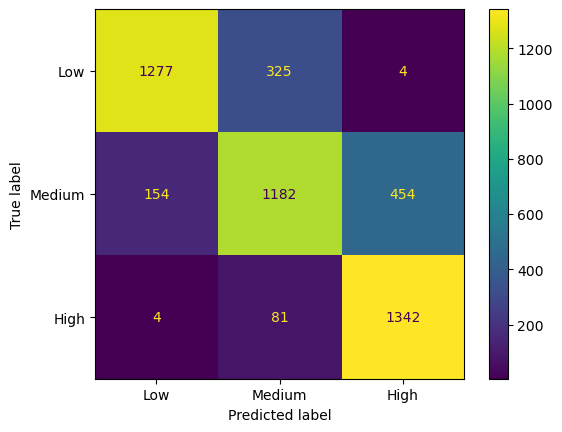

In [10]:
from data_setup import get_category_function
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

to_category, low_cut, high_cut = get_category_function(y_train)

actual_cat = to_category(y_test)
predicted_cat = to_category(y_pred)   # use best_pred for Gradient Boosting

print("Category accuracy:", accuracy_score(actual_cat, predicted_cat))

labels = ["Low", "Medium", "High"]
cm = confusion_matrix(actual_cat, predicted_cat, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot()